<a href="https://colab.research.google.com/github/chev1o/plant-disease-cv/blob/main/notebooks/01_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
KGAT_f76351cfca59205bc36ede508fb4ed4e

# Подготовка датасета

In [1]:
from google.colab import drive
drive.mount('/content/drive')
BASE = "/content/drive/MyDrive/plant-disease"

Mounted at /content/drive


In [ ]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("kaggleapi")

In [ ]:
!pip install -q -U kaggle
!kaggle datasets list -s plantvillage

ref                                                       title                                              size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------  -------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
abdallahalidev/plantvillage-dataset                       PlantVillage Dataset                         4371949460  2019-09-01 11:52:26.883000         132485       1131  0.875            
emmarex/plantdisease                                      PlantVillage Dataset                          689512690  2018-10-30 01:16:23.440000         183946       1293  0.5625           
mohitsingh1804/plantvillage                               PlantVillage                                  857351099  2021-08-20 01:08:58.493000          20937        130  0.625            
soumiknafiul/plantvillage-dataset-labeled                 PlantVi

In [ ]:
!kaggle datasets download -d abdallahalidev/plantvillage-dataset -p /content/drive/MyDrive/plant-disease/data_raw

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:34<00:00, 63.7MB/s]



In [2]:
!unzip -q /content/drive/MyDrive/plant-disease/data_raw/plantvillage-dataset.zip -d /content/data
!ls /content/data

'plantvillage dataset'


In [3]:
!git config --global user.name "chev1o"
!git config --global user.email "180102768+chev1o@users.noreply.github.com"

In [4]:
!git clone https://github.com/chev1o/plant-disease-cv.git
%cd plant-disease-cv

Cloning into 'plant-disease-cv'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 18 (delta 3), reused 6 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (18/18), 6.70 KiB | 2.23 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/plant-disease-cv


# Подготовка данных

In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
import hashlib
from collections import Counter
from tqdm.auto import tqdm
import os

In [6]:
DATA_ROOT = Path("/content/data/plantvillage dataset/color")

In [ ]:
def walk_through_dir(dir_path):
  """
  Walks through dir_path returning its contents.
  Args:
    dir_path (str or pathlib.Path): target directory

  Returns:
    A print out of:
      number of subdiretories in dir_path
      number of images (files) in each subdirectory
      name of each subdirectory
  """
  for dirpath, dirnames, filenames in os.walk(dir_path):
    print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

In [ ]:
walk_through_dir(DATA_ROOT)

There are 38 directories and 0 images in '/content/data/plantvillage dataset/color'.
There are 0 directories and 985 images in '/content/data/plantvillage dataset/color/Corn_(maize)___Northern_Leaf_Blight'.
There are 0 directories and 1909 images in '/content/data/plantvillage dataset/color/Tomato___Late_blight'.
There are 0 directories and 1000 images in '/content/data/plantvillage dataset/color/Tomato___Early_blight'.
There are 0 directories and 373 images in '/content/data/plantvillage dataset/color/Tomato___Tomato_mosaic_virus'.
There are 0 directories and 1645 images in '/content/data/plantvillage dataset/color/Apple___healthy'.
There are 0 directories and 1835 images in '/content/data/plantvillage dataset/color/Squash___Powdery_mildew'.
There are 0 directories and 1771 images in '/content/data/plantvillage dataset/color/Tomato___Septoria_leaf_spot'.
There are 0 directories and 1404 images in '/content/data/plantvillage dataset/color/Tomato___Target_Spot'.
There are 0 directories 

Из всех культур выберем те, которые выращиваются в России больше всего. Мы проанализируем и весь датасет и по выбранным культурам отдельно

In [7]:
TARGET_CROPS = ["Corn_(maize)", "Apple", "Tomato", "Potato", "Pepper,_bell", "Grape"]

In [12]:
OUT_DIR = Path("/content/eda_out")
OUT_DIR.mkdir(exist_ok=True)

print("DATA_ROOT exists:", DATA_ROOT.exists())
print("Всего подпапок:", len([d for d in DATA_ROOT.iterdir() if d.is_dir()]))

DATA_ROOT exists: True
Всего подпапок: 38


## Таблица

In [9]:
def parse_class_name(name: str) -> tuple[str, str]:
    """PlantVillage: 'Tomato___Late_blight' -> ('Tomato', 'Late_blight').
    """
    if "___" not in name:
        return name, "unknown"
    crop, disease = name.split("___", maxsplit=1)
    return crop, disease

rows = []
for cls_dir in sorted(DATA_ROOT.iterdir()):
    if not cls_dir.is_dir():
        continue
    crop, disease = parse_class_name(cls_dir.name)
    for img_path in cls_dir.iterdir():
        if img_path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rows.append({
                "path": str(img_path),
                "class_name": cls_dir.name,
                "crop": crop,
                "disease": disease,
                "size_bytes": img_path.stat().st_size,
            })

df = pd.DataFrame(rows)
print(f"Всего файлов: {len(df)}")
print(f"Классов: {df['class_name'].nunique()}")
print(f"Культур: {df['crop'].nunique()}")
print(f"Болезней: {df['disease'].nunique() - 1}")
df.head()

Всего файлов: 54305
Классов: 38
Культур: 14
Болезней: 20


,path,class_name,crop,disease,size_bytes
0,/content/data/plantvillage dataset/color/Apple...,Apple___Apple_scab,Apple,Apple_scab,11338
1,/content/data/plantvillage dataset/color/Apple...,Apple___Apple_scab,Apple,Apple_scab,16876
2,/content/data/plantvillage dataset/color/Apple...,Apple___Apple_scab,Apple,Apple_scab,13855
3,/content/data/plantvillage dataset/color/Apple...,Apple___Apple_scab,Apple,Apple_scab,9331
4,/content/data/plantvillage dataset/color/Apple...,Apple___Apple_scab,Apple,Apple_scab,17068


In [ ]:
df.crop.value_counts()

,count
crop,
Tomato,18160
Orange,5507
Soybean,5090
Grape,4062
Corn_(maize),3852
Apple,3171
Peach,2657
"Pepper,_bell",2475
Potato,2152


В датасете всего 54 тысячи записи и 14 культур: томат, апельсин, соя, виноград, кукуруза, яблоня, персик, болгарский перец, картофель, вишня, кабачок, клубника (земляника садовая), голубика и малина. Больше всего записей по томату - 18 тысяч


In [ ]:
df.disease.value_counts()

,count
disease,
healthy,15084
Haunglongbing_(Citrus_greening),5507
Bacterial_spot,5421
Tomato_Yellow_Leaf_Curl_Virus,5357
Late_blight,2909
Powdery_mildew,2887
Early_blight,2000
Black_rot,1801
Septoria_leaf_spot,1771


Болезней всего 20 (всего классов 21 - здоровые):

* Haunglongbing (Citrus greening) - **Хаунглонгбинг** (ХЛБ / Жёлтая болезнь побегов / Цитрусовое зеленение) (апельсин).
  * Возбудитель: протеобактерии рода _Candidatus Liberibacter_

* Bacterial_spot - **Бактериальная пятнистость** (персик, томат, перец)
  * Возбудитель: бактерии рода _Xanthomonas_

*  Tomato_Yellow_Leaf_Curl_Virus - **Вирус жёлтой курчавости листьев томата (TYLCV)**  (томат).
    * Возбудитель: вирус _Tomato yellow leaf curl virus_

* Late_blight - **Фитофтороз** (томат, картофель).
  * Возбудитель: гриб _Phytophthora infestans_ (один и тот же возбудитель на томате и картофеле)

* Powdery_mildew - **Мучнистая роса** (кабачок, вишня)
  * Возбудитель: гриб сем. _Erysiphaceae_

* Early_blight - **Альтернариоз** (томат, картофель)
  * Возбудитель: гриб _Alternaria solani_ (один и тот же возбудитель на томате и картофеле)

* Black_rot - **Чёрная гниль** (виноград, яблоня)
  * Возбудитель на винограде: гриб _Guignardia bidwellii / Phyllosticta ampelicida_
  * Возбудитель на яблоне: гриб _Sphaeropsis malorum / Botryosphaeria obtusa_

* Septoria_leaf_spot - **Септориоз** (томат)
  * Возбудитель: гриб _Septoria lycopersici_

* Spider_mites Two-spotted_spider_mite - **Обыкновенный (двупятнистый) паутинный клещ** (томат)
  * Вредитель: клещ _Tetranychus urticae_

* Target_Spot - **Церкоспороз** (томат)
  * Возбудитель: гриб _Pseudocercospora fuligena_

* Esca_(Black_Measles) - **Эска винограда** (виноград)
  * Возбудитель: комплекс патогенных грибов

* Common_rust_ - **Ржавчина (обыкновенная)** (кукуруза)
  * Возбудитель: гриб _Puccinia maydis_

* Leaf_scorch - **Антракноз** (клубника)
  * Возбудитель: грибы рода _Colletotrichum_

* Leaf_blight_(Isariopsis_Leaf_Spot) - **угловатая пятнистость листьев (церкоспороз)** (виноград)
  * Возбудитель: гриб _Pseudocercospora vitis_

* Northern_Leaf_Blight - **Северный гельминтоспориоз или турцикумная пятнистость кукурузы** (кукуруза)
  * Возбудитель: гриб _Helminthosporium turcicum_

* Leaf_Mold - **Кладоспориоз (бурая, или оливковая, пятнистость)** (томат)
  * Возбудитель: гриб _Passalora fulva_

* Apple_scab - **Парша яблони** (яблоня)
  * Возбудитель: гриб _Fusicladium dendriticum / Venturia inaequalis_

* Cercospora_leaf_spot Gray_leaf_spot - **Церкоспороз (или серая пятнистость)** (кукуруза)
  * Возбудитель: грибы рода _Cercospora_
* Tomato_mosaic_virus - **Вирус мозаики томата (ToMV)** (томат)
  * Возбудитель: вирус _Tomato mosaic virus_

* Cedar_apple_rust - **Ржавчина яблони кедровая** (яблоня)
  * Возбудитель: гриб рода _Gymnosporangium_


В датасете присутствуют болезни с разными возбудителями: грибы, вирусы и бактерии. Один класс содержит записи о паутинных клещах - они не вызывают болезни; являются сосущими вредителями.

In [ ]:
df[['crop', 'disease']].value_counts()

crop                     disease                             
Orange                   Haunglongbing_(Citrus_greening)         5507
Tomato                   Tomato_Yellow_Leaf_Curl_Virus           5357
Soybean                  healthy                                 5090
Peach                    Bacterial_spot                          2297
Tomato                   Bacterial_spot                          2127
                         Late_blight                             1909
Squash                   Powdery_mildew                          1835
Tomato                   Septoria_leaf_spot                      1771
                         Spider_mites Two-spotted_spider_mite    1676
Apple                    healthy                                 1645
Tomato                   healthy                                 1591
Blueberry                healthy                                 1502
Pepper,_bell             healthy                                 1478
Tomato                   Target_Spot                             1404
Grape                    Esca_(Black_Measles)                    1383
Corn_(maize)             Common_rust_                            1192
Grape                    Black_rot                               1180
Corn_(maize)             healthy                                 1162
Strawberry               Leaf_scorch                             1109
Grape                    Leaf_blight_(Isariopsis_Leaf_Spot)      1076
Cherry_(including_sour)  Powdery_mildew                          1052
Tomato                   Early_blight                            1000
Potato                   Early_blight                            1000
                         Late_blight                             1000
Pepper,_bell             Bacterial_spot                           997
Corn_(maize)             Northern_Leaf_Blight                     985
Tomato                   Leaf_Mold                                952
Cherry_(including_sour)  healthy                                  854
Apple                    Apple_scab                               630
                         Black_rot                                621
Corn_(maize)             Cercospora_leaf_spot Gray_leaf_spot      513
Strawberry               healthy                                  456
Grape                    healthy                                  423
Tomato                   Tomato_mosaic_virus                      373
Raspberry                healthy                                  371
Peach                    healthy                                  360
Apple                    Cedar_apple_rust                         275
Potato                   healthy                                  152
Name: count, dtype: int64

## Распределение по культурам

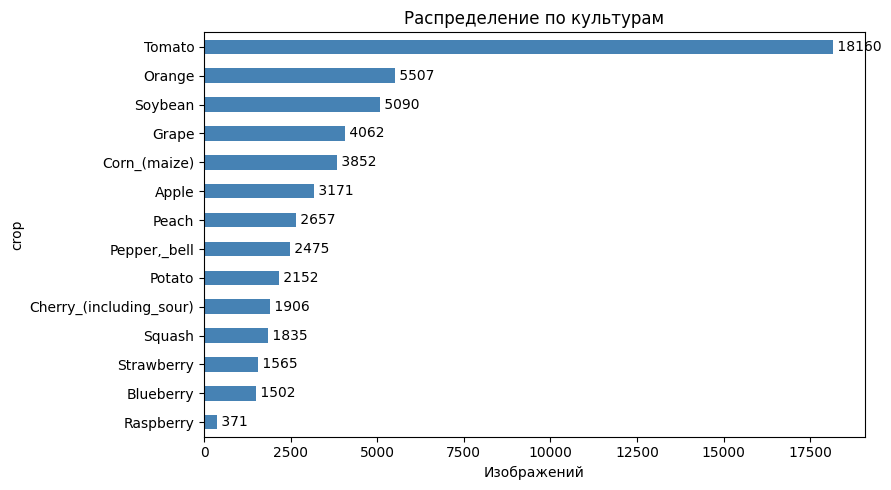

In [15]:
crop_counts = df["crop"].value_counts()

fig, ax = plt.subplots(figsize=(9, 5))
crop_counts.plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Изображений")
ax.set_title("Распределение по культурам")
ax.invert_yaxis()
for i, v in enumerate(crop_counts.values):
    ax.text(v, i, f" {v}", va="center")
plt.tight_layout()
plt.savefig(OUT_DIR / "crop_distribution.png", dpi=120)
plt.show()

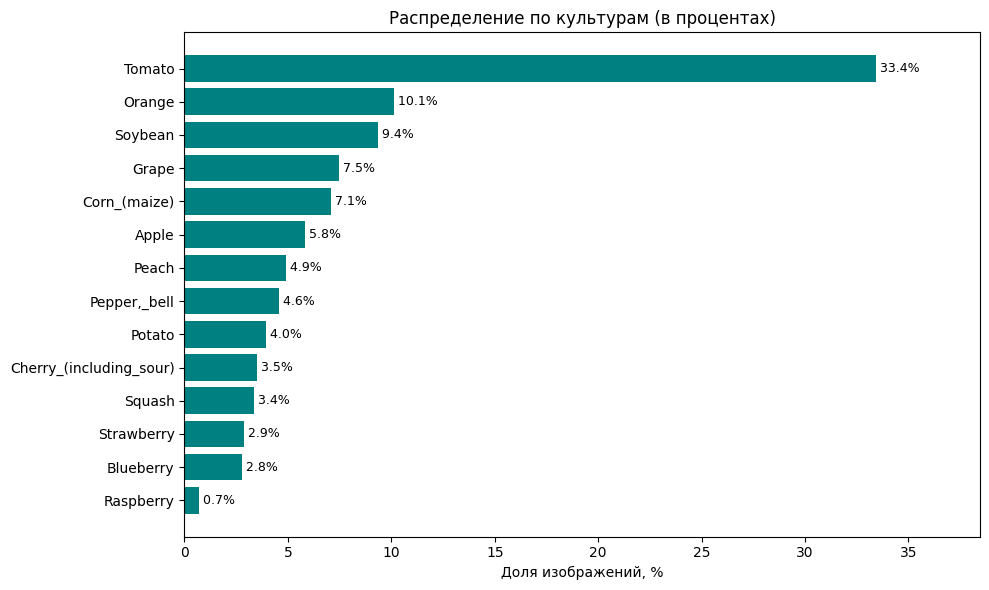

crop
Raspberry                   0.68
Blueberry                   2.77
Strawberry                  2.88
Squash                      3.38
Cherry_(including_sour)     3.51
Potato                      3.96
Pepper,_bell                4.56
Peach                       4.89
Apple                       5.84
Corn_(maize)                7.09
Grape                       7.48
Soybean                     9.37
Orange                     10.14
Tomato                     33.44


In [14]:
crop_pct = (df["crop"].value_counts(normalize=True) * 100).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(crop_pct.index, crop_pct.values, color="teal")
ax.set_xlabel("Доля изображений, %")
ax.set_title("Распределение по культурам (в процентах)")
ax.set_xlim(0, max(crop_pct.values) * 1.15)


for bar, val in zip(bars, crop_pct.values):
    ax.text(val, bar.get_y() + bar.get_height() / 2,
            f" {val:.1f}%", va="center", fontsize=9)

plt.tight_layout()
plt.savefig(OUT_DIR / "crop_distribution_pct.png", dpi=120)
plt.show()

print(crop_pct.round(2).to_string())

Больше всего записей 33% у томата (в датасете из 20 болезней, 9 болезней поражают томат). Наименьшее у малины. По ~4% записей у перца и картофеля.


## Распределение по классам

In [10]:
df_subset = df[df["crop"].isin(TARGET_CROPS)].copy()
print(f"\nSubset: {len(df_subset)} изображений, {df_subset['class_name'].nunique()} классов")
print((df_subset["crop"].value_counts(normalize=True) * 100).sort_values())


Subset: 33872 изображений, 27 классов
crop
Potato           6.353330
Pepper,_bell     7.306920
Apple            9.361715
Corn_(maize)    11.372225
Grape           11.992206
Tomato          53.613604
Name: proportion, dtype: float64


Если смотреть на подвыборку с целевыми культурами, то больше половины датасета занимает томат (53.6%). Записей по другим культурам меньше в 5-9 раз. Всего 6% у картофеля.


В датасете сильный дисбаланс классов. Это важно учесть для обучения и для честной оценки модели


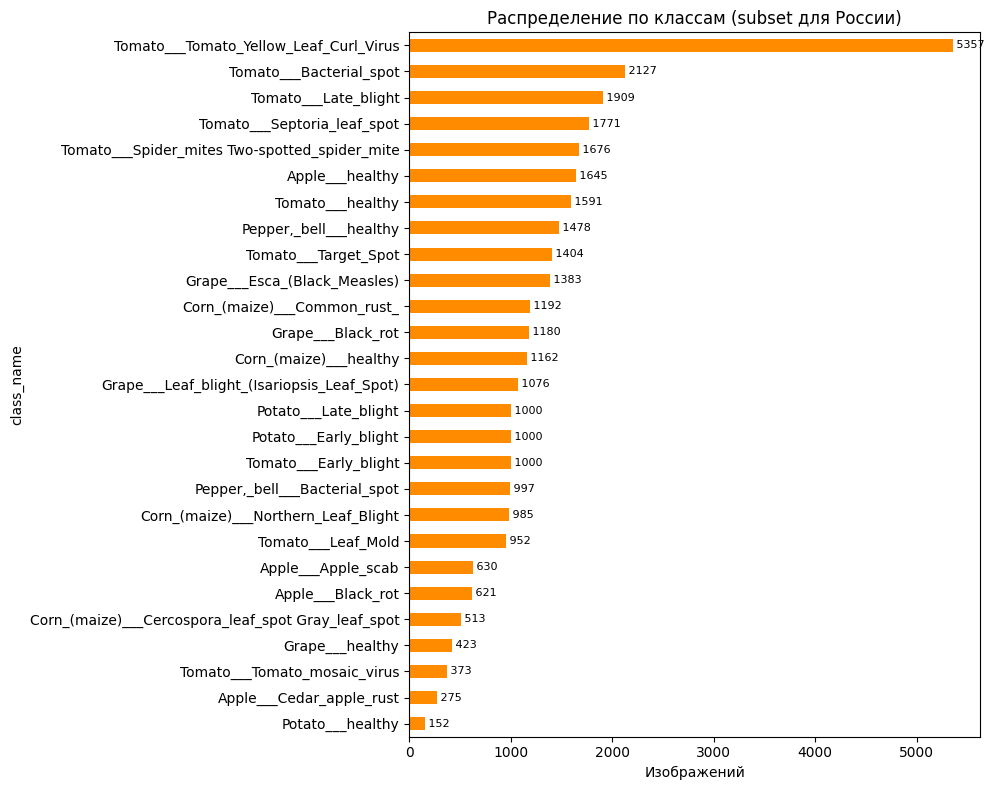

max / min = 35.2x
max: Tomato___Tomato_Yellow_Leaf_Curl_Virus (5357)
min: Potato___healthy (152)


In [13]:
class_counts = df_subset["class_name"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
class_counts.plot(kind="barh", ax=ax, color="darkorange")
ax.set_xlabel("Изображений")
ax.set_title("Распределение по классам (subset для России)")
for i, v in enumerate(class_counts.values):
    ax.text(v, i, f" {v}", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "class_distribution.png", dpi=120)
plt.show()

print(f"max / min = {class_counts.max() / class_counts.min():.1f}x")
print(f"max: {class_counts.idxmax()} ({class_counts.max()})")
print(f"min: {class_counts.idxmin()} ({class_counts.min()})")


class_counts.rename("count").to_csv(OUT_DIR / "class_distribution.csv")

Разница между самым большим классом (Вирус жёлтой курчавости листьев томата) и маленьким (Здоровые растения картофеля) - 35 раз. В целом, топ 5 классов занимают болезни томата.

In [19]:
df_subset["is_healthy"] = df_subset["disease"].str.lower().eq("healthy")

# 1. Таблица по культурам
agg = (df_subset
       .groupby(["crop", "is_healthy"])
       .agg(n_images=("path", "size"),
            n_classes=("class_name", "nunique"))
       .reset_index())

pivot_imgs = agg.pivot(index="crop", columns="is_healthy", values="n_images").fillna(0)
pivot_imgs.columns = ["diseased_imgs", "healthy_imgs"]  # False, True
pivot_cls = agg.pivot(index="crop", columns="is_healthy", values="n_classes").fillna(0)
pivot_cls.columns = ["diseased_classes", "healthy_classes"]

summary = pivot_imgs.join(pivot_cls)
summary["diseased_share_%"] = (
    summary["diseased_imgs"] / (summary["diseased_imgs"] + summary["healthy_imgs"]) * 100
).round(1)
summary["ratio_dis_to_healthy"] = (
    summary["diseased_imgs"] / summary["healthy_imgs"]
).round(2)
summary = summary.sort_values("diseased_imgs", ascending=False)

print("По культурам")
print(summary.to_string())
summary.to_csv(OUT_DIR / "healthy_vs_disease_per_crop.csv")

total_d = int(summary["diseased_imgs"].sum())
total_h = int(summary["healthy_imgs"].sum())
total = total_d + total_h
print(f"\nИтого по subset")
print(f"diseased: {total_d} ({total_d/total*100:.1f}%), классов: "
      f"{int(summary['diseased_classes'].sum())}")
print(f"healthy:  {total_h} ({total_h/total*100:.1f}%), классов: "
      f"{int(summary['healthy_classes'].sum())}")
print(f"ratio diseased/healthy = {total_d/total_h:.2f}x")

По культурам
              diseased_imgs  healthy_imgs  diseased_classes  healthy_classes  diseased_share_%  ratio_dis_to_healthy
crop                                                                                                                
Tomato                16569          1591                 9                1              91.2                 10.41
Grape                  3639           423                 3                1              89.6                  8.60
Corn_(maize)           2690          1162                 3                1              69.8                  2.31
Potato                 2000           152                 2                1              92.9                 13.16
Apple                  1526          1645                 3                1              48.1                  0.93
Pepper,_bell            997          1478                 1                1              40.3                  0.67

Итого по subset
diseased: 27421 (81.0%), классов: 

Если сравнивать по всей подвыборке, класс со здоровыми растениями составляет 19%. Если рассматривать по отдельной культуре, то самый большой дисбаланс у картофеля - значений с болезнями в 13 раз больше, чем значений со здоровыми растениями. Похожая ситуация у томата (разница в 10 раз). У перца, наоборот, картинок со здоровыми растениями больше, чем с болезнью.

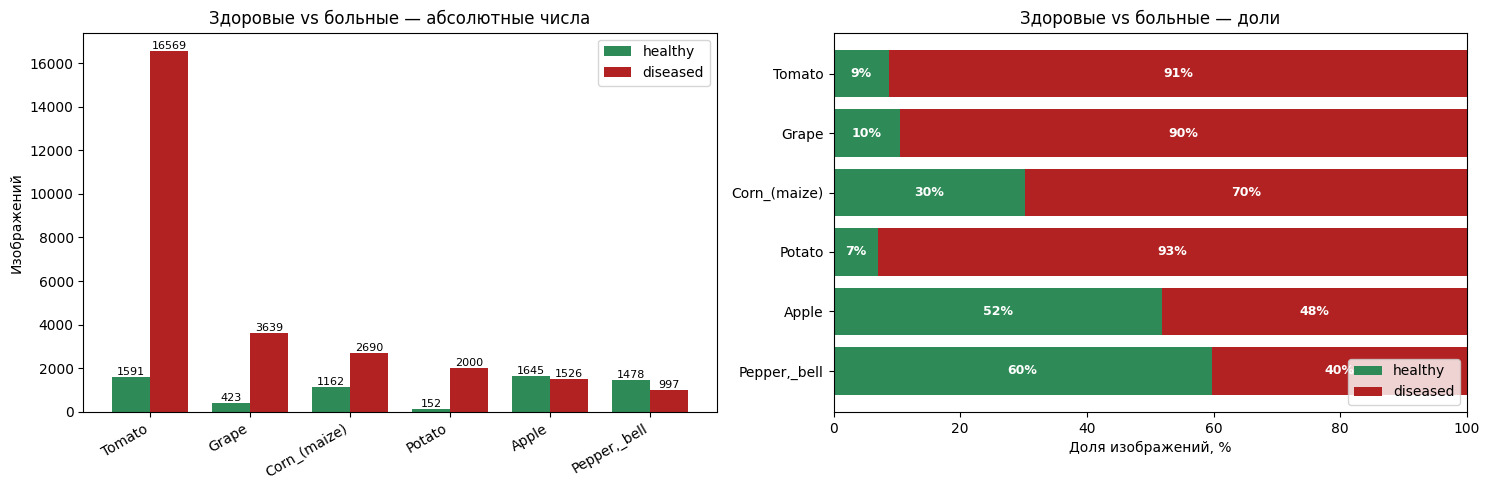

In [20]:
crops = summary.index.tolist()
x = np.arange(len(crops))
w = 0.38

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) абсолютные числа — grouped bar
ax = axes[0]
ax.bar(x - w/2, summary["healthy_imgs"], width=w, label="healthy", color="seagreen")
ax.bar(x + w/2, summary["diseased_imgs"], width=w, label="diseased", color="firebrick")
ax.set_xticks(x)
ax.set_xticklabels(crops, rotation=30, ha="right")
ax.set_ylabel("Изображений")
ax.set_title("Здоровые vs больные — абсолютные числа")
ax.legend()
for i, (h, d) in enumerate(zip(summary["healthy_imgs"], summary["diseased_imgs"])):
    ax.text(i - w/2, h, f"{int(h)}", ha="center", va="bottom", fontsize=8)
    ax.text(i + w/2, d, f"{int(d)}", ha="center", va="bottom", fontsize=8)

# (b) доли — stacked 100%
ax = axes[1]
share_h = summary["healthy_imgs"] / (summary["healthy_imgs"] + summary["diseased_imgs"]) * 100
share_d = 100 - share_h
ax.barh(crops, share_h, color="seagreen", label="healthy")
ax.barh(crops, share_d, left=share_h, color="firebrick", label="diseased")
for i, (h, d) in enumerate(zip(share_h, share_d)):
    ax.text(h/2, i, f"{h:.0f}%", va="center", ha="center",
            color="white", fontsize=9, fontweight="bold")
    ax.text(h + d/2, i, f"{d:.0f}%", va="center", ha="center",
            color="white", fontsize=9, fontweight="bold")
ax.set_xlabel("Доля изображений, %")
ax.set_title("Здоровые vs больные — доли")
ax.set_xlim(0, 100)
ax.legend(loc="lower right")
ax.invert_yaxis()

plt.tight_layout()
plt.savefig(OUT_DIR / "healthy_vs_disease.png", dpi=120)
plt.show()

### Healthy vs Disease: агрономическая интерпретация

| Культура | healthy, шт | diseased, шт | ratio | Комментарий |
|---|---|---|---|---|
| Tomato | 1591 | 16569 | 10.41 | 9 классов болезней |
| Corn | 1162 | 2690 | 2.31 | Northern_Leaf_Blight и Common_rust визуально похожи |
| Apple | 1645 | 1526 | 0.93 | 3 грибные болезни, у Cedar_apple_rust — необходимо наличие промежуточного хозяина можжевельника |
| Grape | 423 | 3639 | 8.60 | Симптомы болезней чаще всего проявляются на листьях позже, чем на гроздях |
| Pepper | 1478 | 997 | 0.67 | Сбалансированные классы |
| Potato | 152 | 2000 | 13.16 | healthy мал — риск зашумить метрику |

**Что это значит для обучения:** если diseased > healthy в несколько раз, `class_weight`
выровняет вклады отдельных классов, но precision по healthy всё равно может
упасть — модель будет склонна выбирать чаще diseased.
Для агронома это осознанный выбор: лучше лишняя тревога, чем пропуск.

## Размеры изображений

Мы посмотрим на выборку из 500 изображений

sizes:   0%|          | 0/500 [00:00<?, ?it/s]

       width  height
count  500.0   500.0
mean   256.0   256.0
std      0.0     0.0
min    256.0   256.0
25%    256.0   256.0
50%    256.0   256.0
75%    256.0   256.0
max    256.0   256.0
Моды: Counter({'RGB': 500})


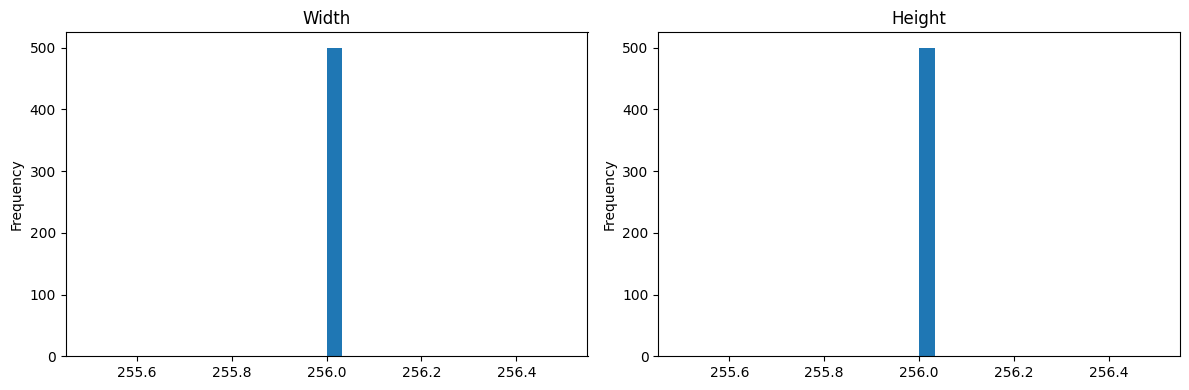

In [25]:
sample_paths = df_subset["path"].sample(n=min(500, len(df_subset)), random_state=42)
sizes, modes = [], []

for p in tqdm(sample_paths, desc="sizes"):
    try:
        with Image.open(p) as im:
            sizes.append(im.size)   # (width, height)
            modes.append(im.mode)
    except Exception as e:
        print("Ошибка на", p, ":", e)

sizes_df = pd.DataFrame(sizes, columns=["width", "height"])
print(sizes_df.describe())
print("Моды:", Counter(modes))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sizes_df["width"].plot(kind="hist", bins=30, ax=ax[0], title="Width")
sizes_df["height"].plot(kind="hist", bins=30, ax=ax[1], title="Height")
plt.tight_layout()
plt.savefig(OUT_DIR / "image_sizes.png", dpi=120)
plt.show()

В датасете изображения размеров 256х256 RGB

## Битые файлы

Проверим по заголовкам

In [26]:
broken = []
for p in tqdm(df_subset["path"], desc="verify"):
    try:
        with Image.open(p) as im:
            im.verify()
    except (UnidentifiedImageError, OSError) as e:
        broken.append({"path": p, "error": str(e)})

broken_df = pd.DataFrame(broken)
print(f"Битых: {len(broken_df)}")
broken_df.to_csv(OUT_DIR / "broken_files.csv", index=False)
broken_df.head()

verify:   0%|          | 0/33872 [00:00<?, ?it/s]

Битых: 0


""


Проверим сами картинки (по пикселям)

In [27]:
broken = []
for p in tqdm(df_subset["path"], desc="verify"):
    try:
        with Image.open(p) as im:
            im.load()
    except (UnidentifiedImageError, OSError) as e:
        broken.append({"path": p, "error": str(e)})

broken_df = pd.DataFrame(broken)
print(f"Битых: {len(broken_df)}")
broken_df.to_csv(OUT_DIR / "broken_files.csv", index=False)
broken_df.head()

verify:   0%|          | 0/33872 [00:00<?, ?it/s]

Битых: 0


""


У нас нет битых картинок

## Дубликаты

In [28]:
def md5(path: str, chunk: int = 1 << 20) -> str:
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk_data in iter(lambda: f.read(chunk), b""):
            h.update(chunk_data)
    return h.hexdigest()

# считаем хеши только на subset
df_subset["md5"] = [md5(p) for p in tqdm(df_subset["path"], desc="md5")]

dup_groups = df_subset.groupby("md5").filter(lambda g: len(g) > 1)
print(f"Файлов в группах дублей: {len(dup_groups)}")
print(f"Уникальных хешей с дублями: {dup_groups['md5'].nunique()}")

# пример
if len(dup_groups):
    first_hash = dup_groups["md5"].iloc[0]
    print("\nПример группы:")
    print(dup_groups[dup_groups["md5"] == first_hash][["path", "class_name"]])

dup_groups[["path", "class_name", "md5"]].to_csv(OUT_DIR / "exact_duplicates.csv", index=False)

md5:   0%|          | 0/33872 [00:00<?, ?it/s]

Файлов в группах дублей: 42
Уникальных хешей с дублями: 21

Пример группы:
                                                   path       class_name
1668  /content/data/plantvillage dataset/color/Apple...  Apple___healthy
2029  /content/data/plantvillage dataset/color/Apple...  Apple___healthy


Удалим дубликаты

In [29]:
before = len(df_subset)
df_clean = df_subset.drop_duplicates(subset="md5", keep="first").copy()
print(f"Было: {before}, стало: {len(df_clean)}, удалено: {before - len(df_clean)}")

Было: 33872, стало: 33851, удалено: 21


## Примеры

Выберем классы, где симптомы разных болезней похожи, и посмотрим на пример картинок

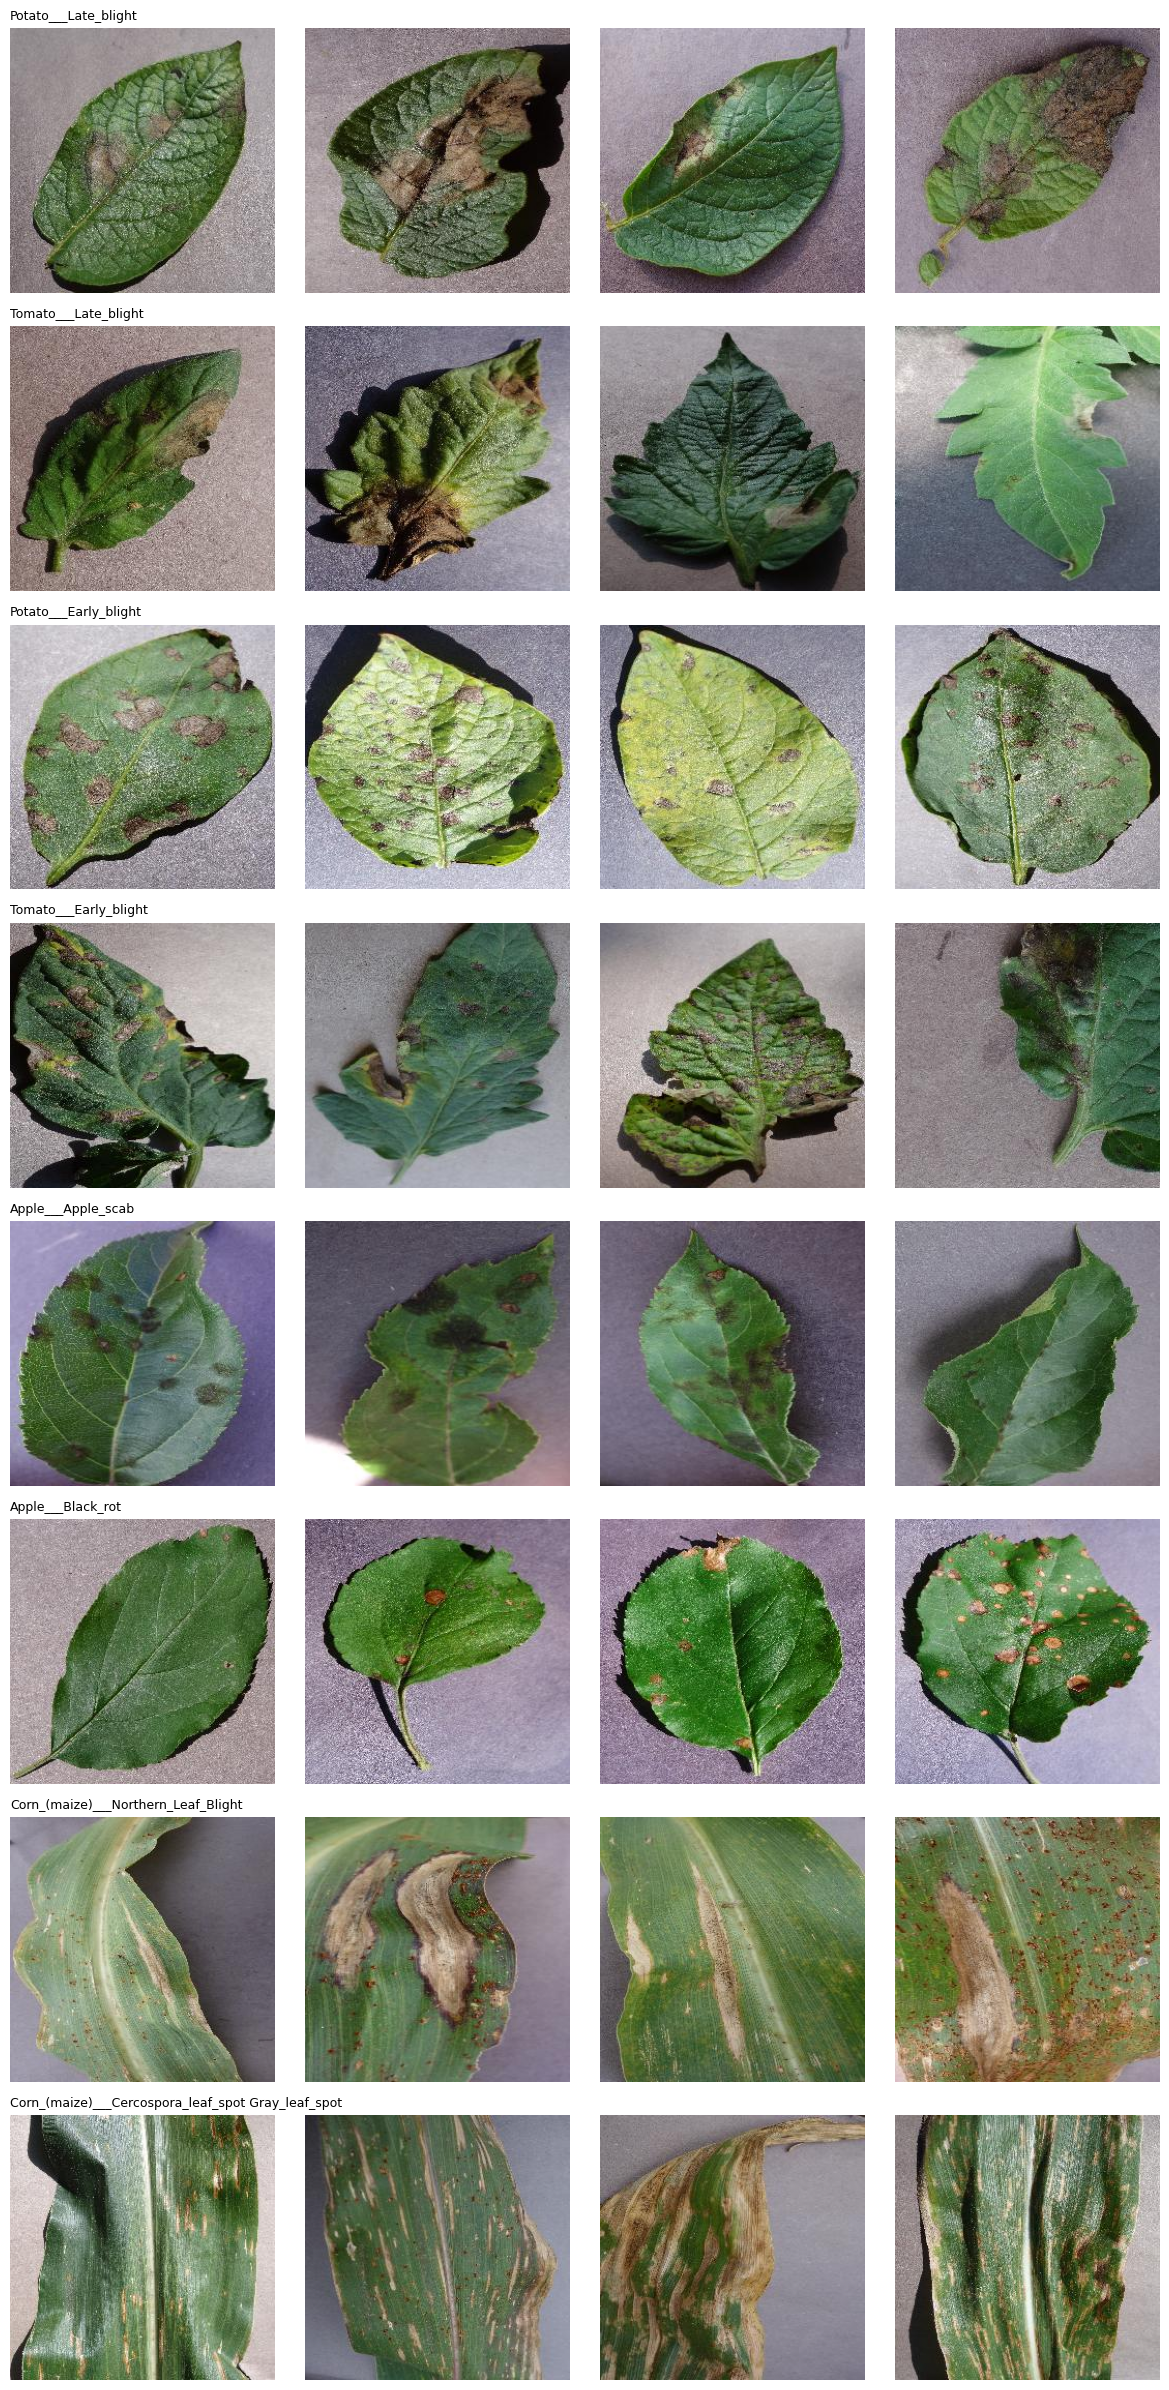

In [30]:
GALLERY_CLASSES = [
    "Potato___Late_blight",
    "Tomato___Late_blight",
    "Potato___Early_blight",
    "Tomato___Early_blight",
    "Apple___Apple_scab",
    "Apple___Black_rot",
    "Corn_(maize)___Northern_Leaf_Blight",
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
]

n_per = 4
fig, axes = plt.subplots(len(GALLERY_CLASSES), n_per,
                         figsize=(3 * n_per, 3 * len(GALLERY_CLASSES)))
for i, cls in enumerate(GALLERY_CLASSES):
    paths = df_subset[df_subset["class_name"] == cls]["path"].sample(
        n=n_per, random_state=42).tolist()
    for j, p in enumerate(paths):
        with Image.open(p) as im:
            axes[i, j].imshow(im)
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(cls, fontsize=9, loc="left")
plt.tight_layout()
plt.savefig(OUT_DIR / "gallery_confusable_pairs.png", dpi=120)
plt.show()

Наибольшее сходство у томата и картофеля по **альтернариозу и фитофторозу**. Эти культуры относятся к одному семейству (Пасленовые), и возбудители одинаковые. Если модель будет ошибаться в культуре, но не в болезни - ошибка не критична.

**Парша яблони и черная гниль** - похожие округлые пятна по цвету и по размеру. У парши пятна сначала светло-зеленые расплывчатые, потом покрываются бурым налетом. У черной гнили пятна красновато-бурые или бурые. Но пятна концентрические.

**Церкоспороз и северный гельминтоспориоз** - похожие вытянутые пятна сливающиеся. При церкоспорозе образуются пятна с желтыми хлоротическими ореолами на листьях, потом могут охватить всю поверхность листа. При гельминтоспориозе крупные образуются веретеновидные светло-серые пятна с более темными краями, с темным сажистым налетом, позже пятна сливаются и листья засыхают.


# Выводы

## Данные и EDA (PlantVillage)

### Общая статистика
Исходный датасет: **54 305 изображений**, 14 культур, 38 классов (20 болезней + здоровые).
Для проекта выбрано **6 культур, релевантных для РФ**: томат, картофель, кукуруза, яблоня, перец, виноград.
Итоговый subset: **33 851 изображение** (после удаления 21 точного дубликата по md5), **27 классов**.

### Дисбаланс классов и культур
*   **Культуры**: Томат доминирует (53.6% subset). Остальные культуры занимают от 6% до 12%. Это требует осторожности при оценке модели.
*   **Классы**: Разница между самым частым (`Tomato___Tomato_Yellow_Leaf_Curl_Virus` — 5357) и самым редким (`Potato___healthy` — 152) классом — **35.2 раз**.
*   **Здоровые vs Больные**: В целом больных в 4.25 раз больше (81% vs 19%). Однако по культурам картина разная:
    *   *Картофель*: самый большой дисбаланс (13.16x в сторону болезней, healthy всего 152 фото).
    *   *Томат*: сильный дисбаланс (10.41x).
    *   *Перец и Яблоня*: сбалансированы (healthy даже немного больше).

### Свойства изображений
*   Все изображения: **256×256, RGB**. Битых файлов нет. Это позволяет использовать стандартный `Resize(224)` для EfficientNet-B0 без потери информации.

### Агрономический контекст и визуальные сходства
*   **Семейство Пасленовые (_Solanaceae_)**: Томат и картофель поражаются *одними и теми же* возбудителями — фитофторозом (*Phytophthora infestans*) и альтернариозом (*Alternaria solani*). Модель будет путать культуры (`Tomato___Late_blight` vs `Potato___Late_blight`). **С агрономической точки зрения это не критичная ошибка**: важнее знать *болезнь*, а не культуру.
*   **Похожие симптомы на одной культуре**:
  * Церкоспороз кукурузы (желтые ореолы) и северный гельминтоспориоз (веретеновидные серые пятна с темным налетом) — классическая сложная пара.
  * Парша яблони и черная гниль имеют схожие округлые пятна, но у черной гнили они концентрические.
*   **Разные типы патогенов**: В датасете смешаны грибы, бактерии, вирусы. Отдельно стоит класс `Spider_mites` — это **не болезнь, а вредитель** (паутинный клещ). Модель должна научиться отличать его от инфекционных болезней.

### Ограничения датасета (Важно для продакшена)
1.  **Лабораторные условия**: PlantVillage снят на однородном фоне, один лист в кадре. В поле будут тени, фон, несколько листьев.
2.  **Near-duplicates**: Помимо 21 точного дубликата, в датасете есть снимки одних и тех же листьев под разными углами. Мы не удаляли их (pHash-фильтрация — план на будущее), но при сплите использовали **стратификацию с группировкой**, чтобы минимизировать утечку.
3.  **Малые классы**: `Potato___healthy` (152) — метрики по нему будут иметь широкий доверительный интервал.
